<a href="https://colab.research.google.com/github/julianovale/PO1/blob/main/PO1_000_Problema_Cervejaria_Artesanal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ortools

# Problema da Cervejaria Artesanal (Pilsen e Stout)

Uma cervejaria artesanal produz dois estilos de cerveja em lotes padronizados de 100 litros: **Pilsen** e **Stout**.

A **Pilsen** utiliza uma base leve de malte, mas leva uma carga generosa de **lúpulo** para garantir amargor e aroma refrescante. Já a **Stout** exige o triplo de **malte** (para corpo e notas torradas), porém utiliza menos lúpulo na fervura.

Para o planejamento semanal da brassagem, o mestre cervejeiro precisa definir quantos lotes de cada estilo produzir para **maximizar o lucro**, respeitando os limites de estoque de malte e lúpulo disponíveis na semana.

## Tabela de Consumo de Insumos e Lucro

| Estilo de Cerveja | Malte (kg/lote) | Lúpulo (g/lote) | Lucro (R$/lote) |
| :--- | :--- | :--- | :--- |
| **Pilsen** | 10 | 300 | 500,00 |
| **Stout** | 30 | 100 | 600,00 |
| **Disponibilidade Semanal** | **120** | **1.200** | - |

## Modelo Matemático

**Variáveis de Decisão:**
* $x_1$: Quantidade de lotes de cerveja **Pilsen** a produzir na semana
* $x_2$: Quantidade de lotes de cerveja **Stout** a produzir na semana

**Função Objetivo (Maximizar Lucro Semanal):**
$$\max Z = 500x_1 + 600x_2$$

**Restrições:**
* **Disponibilidade de Malte (kg):** $10x_1 + 30x_2 \le 120$
* **Disponibilidade de Lúpulo (g):** $300x_1 + 100x_2 \le 1200$
* **Não-negatividade:** $x_1, x_2 \ge 0$

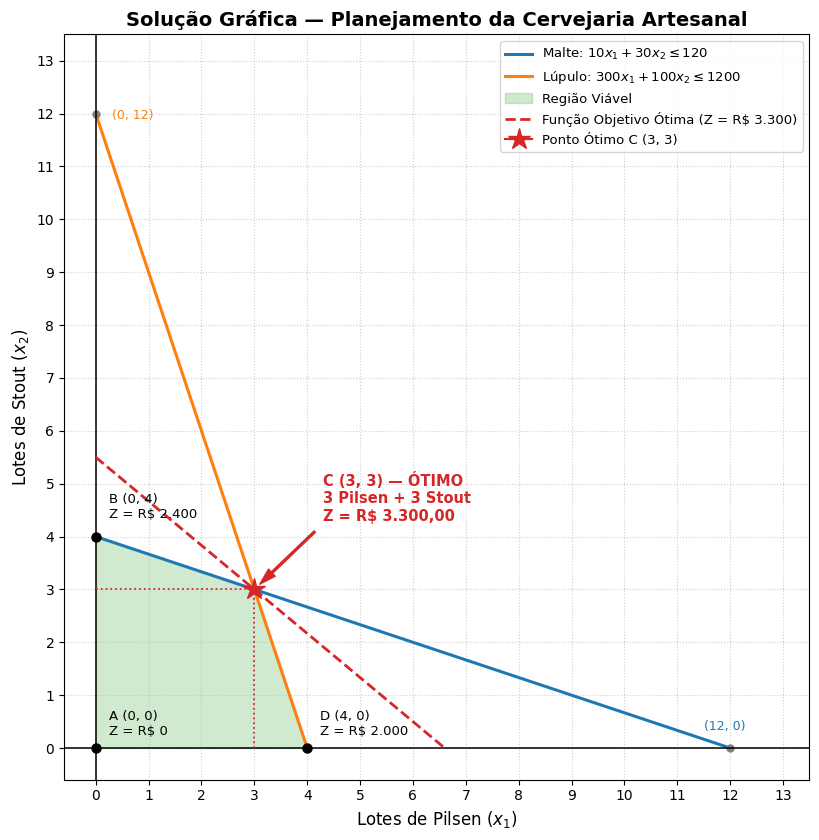

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 8.5))

# 1. Restrição de Malte: 10*x1 + 30*x2 <= 120  (interceptos em (0, 4) e (12, 0))
x1_malte = np.linspace(0, 12, 500)
x2_malte = (120 - 10 * x1_malte) / 30

# 2. Restrição de Lúpulo: 300*x1 + 100*x2 <= 1200  (interceptos em (0, 12) e (4, 0))
x1_lupulo = np.linspace(0, 4, 500)
x2_lupulo = (1200 - 300 * x1_lupulo) / 100

# Plotagem das retas de restrição completas de eixo a eixo
ax.plot(x1_malte, x2_malte, label=r'Malte: $10x_1 + 30x_2 \leq 120$', color='#1f77b4', linewidth=2.2)
ax.plot(x1_lupulo, x2_lupulo, label=r'Lúpulo: $300x_1 + 100x_2 \leq 1200$', color='#ff7f0e', linewidth=2.2)

# Marcação discreta nos interceptos externos das restrições
ax.plot([12, 0], [0, 12], 'o', color='gray', markersize=5)
ax.annotate('(12, 0)', xy=(12, 0), xytext=(11.5, 0.35), fontsize=9, color='#1f77b4')
ax.annotate('(0, 12)', xy=(0, 12), xytext=(0.3, 11.9), fontsize=9, color='#ff7f0e')

# Eixos de não-negatividade
ax.axhline(0, color='black', linewidth=1.1)
ax.axvline(0, color='black', linewidth=1.1)

# Preenchimento da Região Viável (x1 varia de 0 até 4)
x1_viavel = np.linspace(0, 4, 500)
x2_teto = np.minimum((120 - 10 * x1_viavel) / 30, (1200 - 300 * x1_viavel) / 100)
ax.fill_between(x1_viavel, 0, x2_teto, color='#2ca02c', alpha=0.22, label='Região Viável')

# Curva de nível (Isoprofit) Ótima da Função Objetivo: Z = 500*x1 + 600*x2 = 3300
x1_otimo = np.linspace(0, 6.6, 300)
x2_z_otimo = (3300 - 500 * x1_otimo) / 600
ax.plot(x1_otimo, x2_z_otimo, '--', color='#d62728', linewidth=2, label='Função Objetivo Ótima (Z = R$ 3.300)')

# Projeções tracejadas do ponto ótimo nos eixos
ax.plot([3, 3], [0, 3], ':', color='#d62728', linewidth=1.3)
ax.plot([0, 3], [3, 3], ':', color='#d62728', linewidth=1.3)

# Demais vértices da Região Viável
vertices = [
    (0, 0, 'A (0, 0)\nZ = R$ 0', (0.25, 0.25)),
    (0, 4, 'B (0, 4)\nZ = R$ 2.400', (0.25, 4.35)),
    (4, 0, 'D (4, 0)\nZ = R$ 2.000', (4.25, 0.25))
]

for vx, vy, texto, pos_texto in vertices:
    ax.plot(vx, vy, 'ko', markersize=6.5)
    ax.annotate(texto, xy=(vx, vy), xytext=pos_texto, fontsize=9.5)

# Destaque para o Cotovelo Ótimo C (3, 3)
ax.plot(3, 3, marker='*', color='#d62728', markersize=16, zorder=5, label='Ponto Ótimo C (3, 3)')
ax.annotate('C (3, 3) — ÓTIMO\n3 Pilsen + 3 Stout\nZ = R$ 3.300,00',
            xy=(3, 3), xytext=(4.3, 4.3),
            fontsize=10.5, fontweight='bold', color='#d62728',
            arrowprops=dict(facecolor='#d62728', edgecolor='#d62728', shrink=0.08, width=1.4, headwidth=7))

# Proporção 1:1 e enquadramento com folga para todos os pontos
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(-0.6, 13.5)
ax.set_ylim(-0.6, 13.5)
ax.set_xticks(np.arange(0, 14, 1))
ax.set_yticks(np.arange(0, 14, 1))

ax.set_xlabel('Lotes de Pilsen ($x_1$)', fontsize=12)
ax.set_ylabel('Lotes de Stout ($x_2$)', fontsize=12)
ax.set_title('Solução Gráfica — Planejamento da Cervejaria Artesanal', fontsize=14, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()

plt.show()